<a href="https://colab.research.google.com/github/roser740/Data-Analytics/blob/main/TASQUES%20S13/ANALISI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ANÀLISI DE LA QUALITAT DE L'AIRE A LA PLANA DE VIC**

# **💢 ANÀLISI DE LES DADES DE CONTAMINACIÓ**

# **📚 Llibreries**

In [129]:

import pandas as pd # llibreria per gestionar dataframes
import numpy as np # llibreria per computació numèrica i científica
import codecs # mòdul per codificar i descodificar dades en diferents formats
import seaborn as sns # llibreria de visualització de dades
import matplotlib.pyplot as plt # llibreria per fer gràfiques

from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

# **⭕ Funcions generals**

In [130]:
def mostrar_dataframe(df, títol):
#Presenta les dades en format tabular amb el títol indicat

    # Mostrem títol
    print("\n" + "="*100)
    print(títol)
    print("="*100)
    # La funció display mostra les dades del dataframe en format taula.
    # Utilitzem la propietat style per amagar la columna de l'índex.
    display(df)

##🟢**Càrrega de les dades processades (data_clean)**

In [131]:
url = "https://github.com/roser740/Data-Analytics/raw/main/TASQUES%20S13/DADES_PROCESSADES/"

In [132]:

tipus_columnes = {
    "CODI_INE": "string",
    "MAX_OZO_8h": "float64",
    "SUPERA_LIMIT_UE": "Int8",
}
df_finestres = pd.read_csv(url+"finestres_ozo.csv",
                           na_values=["\\N"],
                           dtype=tipus_columnes,
                           parse_dates=["DATA"],
                           sep = ",", header=0,
                           encoding='latin1',
                           low_memory = False)
df_finestres.head(10)


,DATA,MAX_OZO_8h,CODI_INE,SUPERA_LIMIT_UE
0,1992-03-26,48.67,08298,0
1,1992-03-27,68.38,08298,0
2,1992-03-28,88.75,08298,0
3,1992-03-29,84.50,08298,0
4,1992-03-30,88.38,08298,0
5,1992-03-31,85.00,08298,0
6,1992-04-01,88.12,08298,0
7,1992-04-02,82.38,08298,0
8,1992-04-03,80.00,08298,0
9,1992-04-04,54.00,08298,0


In [133]:
df_finestres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50643 entries, 0 to 50642
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   DATA             50643 non-null  datetime64[ns]
 1   MAX_OZO_8h       48077 non-null  float64       
 2   CODI_INE         50643 non-null  string        
 3   SUPERA_LIMIT_UE  48077 non-null  Int8          
dtypes: Int8(1), datetime64[ns](1), float64(1), string(1)
memory usage: 1.3 MB


In [134]:
print("Valors nuls" )
print(df_finestres.isna().sum())

Valors nuls
DATA                  0
MAX_OZO_8h         2566
CODI_INE              0
SUPERA_LIMIT_UE    2566
dtype: int64


In [135]:
tipus_columnes = {
    "CODI INE": "string",
    "MUNICIPI": "string",
    "CODI COMARCA": "string",
    "NOM COMARCA" : "string"
}
df_municipis = pd.read_csv(url+"municipis.csv",
                           na_values=["\\N"],
                           dtype=tipus_columnes,
                           sep = ",", header=0,
                           encoding="utf-8",
                           low_memory = False)
df_municipis.columns = ["CODI_INE","MUNICIPI","CODI_COMARCA","NOM_COMARCA"]
df_municipis.head(10)

,CODI_INE,MUNICIPI,CODI_COMARCA,NOM_COMARCA
0,08298,Vic,24,Osona
1,08112,Manlleu,24,Osona
2,08283,Tona,24,Osona
3,08113,Manresa,07,Bages
4,08019,Barcelona,13,Barcelonès


In [136]:
df = pd.merge(df_finestres, df_municipis, left_on='CODI_INE', right_on='CODI_INE',how = 'inner')
df

,DATA,MAX_OZO_8h,CODI_INE,SUPERA_LIMIT_UE,MUNICIPI,CODI_COMARCA,NOM_COMARCA
0,1992-03-26,48.67,08298,0,Vic,24,Osona
1,1992-03-27,68.38,08298,0,Vic,24,Osona
2,1992-03-28,88.75,08298,0,Vic,24,Osona
3,1992-03-29,84.50,08298,0,Vic,24,Osona
4,1992-03-30,88.38,08298,0,Vic,24,Osona
...,...,...,...,...,...,...,...
50638,2026-11-14,59.12,08019,0,Barcelona,13,Barcelonès
50639,2026-11-15,49.50,08019,0,Barcelona,13,Barcelonès
50640,2026-11-16,49.62,08019,0,Barcelona,13,Barcelonès
50641,2026-11-17,44.25,08019,0,Barcelona,13,Barcelonès


In [137]:

tipus_columnes = {
    "CODI EOI": "string",
    "ESTACIO_METEO": "string",
    "MAGNITUD": "Int8",
    "value": "float64",
    "HORA": "Int8"
}
df_qualitat = pd.read_csv("registres_qualitat.csv",
                           na_values=["\\N"],
                           dtype=tipus_columnes,
                           parse_dates=["DATA"],
                           sep = ",", header=0,
                           encoding='latin1',
                           low_memory = False)
df_qualitat.columns = ["CODI_EOI","ESTACIO_METEO","MAGNITUD","DATA", "HORA", "VALUE"]
df_qualitat.head(10)


,CODI_EOI,ESTACIO_METEO,MAGNITUD,DATA,HORA,VALUE
0,08019043,<NA>,14,1996-05-08,0,13.0
1,08019043,<NA>,14,1996-05-08,1,33.0
2,08019043,<NA>,14,1996-05-08,2,45.0
3,08019043,<NA>,14,1996-05-08,3,44.0
4,08019043,<NA>,14,1996-05-08,4,37.0
5,08019043,<NA>,14,1996-05-08,5,16.0
6,08019043,<NA>,14,1996-05-08,6,17.0
7,08019043,<NA>,14,1996-05-08,7,24.0
8,08019043,<NA>,14,1996-05-08,8,25.0
9,08019043,<NA>,14,1996-05-08,9,23.0


##🟢**Kruskal-Wallis + Post-hoc**

In [138]:

from scipy import stats

# Suposem que df té columnes: ['DATA', 'MUNICIPI', 'MAX_OZO_8h']
municipis = ["Barcelona", "Manresa", "Vic"]
df_sub = df[(df["MUNICIPI"].isin(municipis)) & (df["DATA"].dt.year.between(2001, 2026))].dropna(subset=["MAX_OZO_8h"]).copy()

# 1. Resum descriptiu robust (Mediana, IQR i Percentil 90)
resum = df_sub.groupby("MUNICIPI")["MAX_OZO_8h"].agg(
    dies="count",
    mediana="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    maxim="max",
)
resum["IQR"] = resum["q75"] - resum["q25"]
print(resum.round(2))

# 2. Test global de Kruskal-Wallis
grups = [df_sub.loc[df_sub["MUNICIPI"] == m, "MAX_OZO_8h"] for m in municipis]
h_stat, p_kw = stats.kruskal(*grups)
print(f"\nKruskal-Wallis: H = {h_stat:.2f}, p-valor = {p_kw:.4e}")

# 3. Comparació per parelles (Mann-Whitney U + Bonferroni per 3 comparacions)
parelles = [("Vic", "Manresa"), ("Vic", "Barcelona"), ("Manresa", "Barcelona")]
for m1, m2 in parelles:
  g1 = df_sub.loc[df_sub["MUNICIPI"] == m1, "MAX_OZO_8h"]
  g2 = df_sub.loc[df_sub["MUNICIPI"] == m2, "MAX_OZO_8h"]
  u_stat, p_val = stats.mannwhitneyu(g1, g2, alternative="two-sided")
  p_adj = min(p_val * len(parelles), 1.0)
  dif_med = g1.median() - g2.median()
  print(
      f"{m1} vs {m2}: dif. medianes = {dif_med:+.2f} ug/m3 | p-valor ajustat ="
      f" {p_adj:.4e}"
  )

           dies  mediana    q25     q75     p90   maxim    IQR
MUNICIPI                                                      
Barcelona  8624    55.25  36.75   69.90   82.12  143.50  33.14
Manresa    9250    65.12  36.88   84.75  100.12  161.25  47.87
Vic        9098    81.12  53.12  103.62  124.50  194.25  50.50

Kruskal-Wallis: H = 2648.23, p-valor = 0.0000e+00
Vic vs Manresa: dif. medianes = +16.00 ug/m3 | p-valor ajustat = 6.9358e-229
Vic vs Barcelona: dif. medianes = +25.87 ug/m3 | p-valor ajustat = 0.0000e+00
Manresa vs Barcelona: dif. medianes = +9.87 ug/m3 | p-valor ajustat = 1.0291e-88


In [139]:
mesos_estiu = [ 6, 7, 8]
df_estiu = df_sub[df_sub["DATA"].dt.month.isin(mesos_estiu)].copy()

resum_estiu = df_estiu.groupby("MUNICIPI")["MAX_OZO_8h"].agg(
    dies="count",
    mediana="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    maxim="max",
)
resum_estiu["IQR"] = resum_estiu["q75"] - resum_estiu["q25"]
print(resum_estiu.round(2))

           dies  mediana    q25     q75     p90   maxim    IQR
MUNICIPI                                                      
Barcelona  2168    67.12  57.12   78.75   90.66  143.50  21.63
Manresa    2347    90.88  78.88  103.62  114.25  161.25  24.74
Vic        2285   114.38  98.62  131.38  145.25  194.25  32.76


/tmp/ipykernel_417/2852838225.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


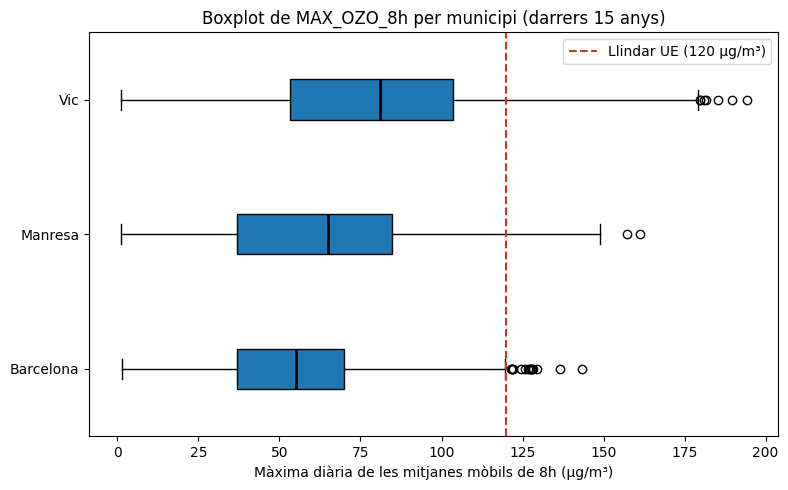

In [140]:
municipis = ["Barcelona", "Manresa", "Vic"]
dades = [
    df_sub.loc[df_sub["MUNICIPI"] == m, "MAX_OZO_8h"].dropna()
    for m in municipis
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    dades,
    vert=False,
    labels=municipis,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
ax.axvline(
    120,
    color="#C0392B",
    linestyle="--",
    linewidth=1.5,
    label="Llindar UE (120 µg/m³)",
)
ax.set_xlabel("Màxima diària de les mitjanes mòbils de 8h (µg/m³)")
ax.set_title("Boxplot de MAX_OZO_8h per municipi (darrers 15 anys)")
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_417/1246520716.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


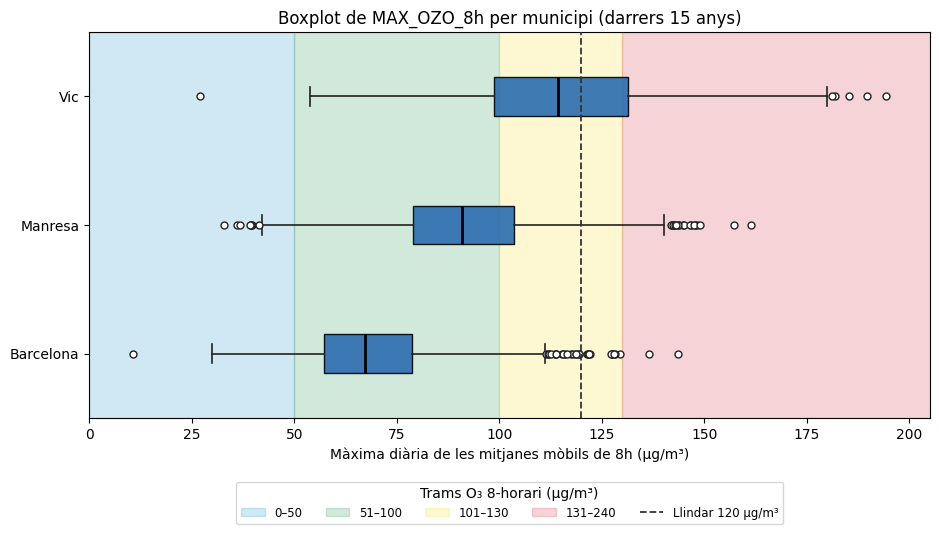

In [141]:
import matplotlib.pyplot as plt

mesos_estiu = [ 6, 7, 8]
#df_estiu = df_sub[df_sub["DATA"].dt.month.isin(mesos_estiu)].copy()
#     df_sub.loc[(df_sub["MUNICIPI"] == m) & (df_sub["DATA"].dt.month.isin(mesos_estiu)), "MAX_OZO_8h"].dropna()
#    df_sub.loc[df_sub["MUNICIPI"] == m, "MAX_OZO_8h"].dropna()

municipis = ["Barcelona", "Manresa", "Vic"]
dades = [
    df_sub.loc[(df_sub["MUNICIPI"] == m) & (df_sub["DATA"].dt.month.isin(mesos_estiu)), "MAX_OZO_8h"].dropna()
    for m in municipis
]

# Trams 8-horaris d'O3 (µg/m3) segons la taula de Catalunya: (inici, fi, etiqueta, color)
trams_8h = [
    (0, 50, "0–50", "#2998CC"),
    (50, 100, "51–100", "#2E9E5B"),
    (100, 130, "101–130", "#F7E336"),
    (130, 205, "131–240", "#D93B48"),
    # Si vols incloure trams superiors en ampliar l'eix X:
    #(240, 380, "241–380", "#6B0F1A"),
    #(380, 420, ">380", "#9B59B6"),
]

fig, ax = plt.subplots(figsize=(9.5, 5.5))

# 1. Franges de fons dels trams 8-horaris
for x0, x1, label, color in trams_8h:
  ax.axvspan(x0, x1, color=color, alpha=0.22, zorder=0, label=label)

# 2. Boxplot per sobre del fons
bp = ax.boxplot(
    dades,
    vert=False,
    labels=municipis,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="#222222", linewidth=1.2),
    capprops=dict(color="#222222", linewidth=1.2),
    flierprops=dict(
        marker="o",
        markersize=5,
        markerfacecolor="white",
        markeredgecolor="#222222",
    ),
    zorder=3,
)

for patch in bp["boxes"]:
  patch.set_facecolor("#2B6CB0")
  patch.set_edgecolor("black")
  patch.set_alpha(0.9)

# Línia de referència del llindar de 120 µg/m3 (dins del tram groc 101–130)
ax.axvline(
    120,
    color="#333333",
    linestyle="--",
    linewidth=1.3,
    zorder=4,
    label="Llindar 120 µg/m³",
)

ax.set_xlim(0, 205)
ax.set_xlabel("Màxima diària de les mitjanes mòbils de 8h (µg/m³)")
ax.set_title("Boxplot de MAX_OZO_8h per municipi (darrers 15 anys)")

ax.legend(
    title="Trams O₃ 8-horari (µg/m³)",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=5,
    frameon=True,
    fontsize=8.5,
)

plt.tight_layout()
plt.show()

Número hores a cada nivell de la EEA

/tmp/ipykernel_417/2584036482.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


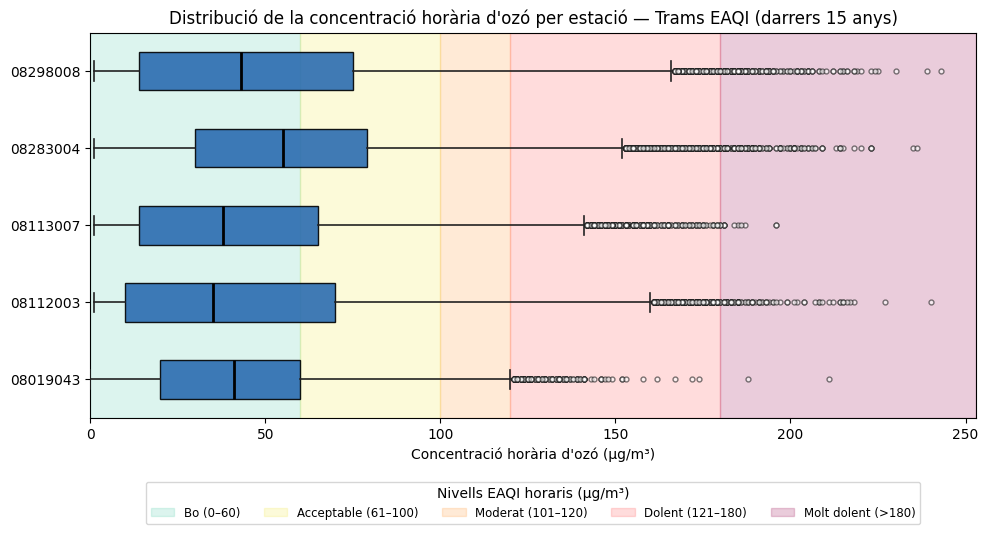

In [143]:


# 1. Preparem les dades horàries (darrers 15 anys)
df_h = df_qualitat.copy()
df_h["DATA"] = pd.to_datetime(df_h["DATA"])
df_h = df_h[df_h["DATA"].dt.year >= 2011].dropna(subset=["VALUE"])
# Si vols filtrar només estiu:
# df_h = df_h[df_h["DATA"].dt.month.isin([6, 7, 8])]

estacions = sorted(df_h["CODI_EOI"].unique())
dades = [
    df_h.loc[df_h["CODI_EOI"] == e, "VALUE"].values for e in estacions
]

# 2. Franges EAQI horàries per a O3 (µg/m3): (inici, fi, etiqueta, color)
xmax = max(200, df_h["VALUE"].max() + 10)
franges_eea_horaries = [
    (0, 60, "Bo (0–60)", "#50CCAA"),
    (60, 100, "Acceptable (61–100)", "#F0E641"),
    (100, 120, "Moderat (101–120)", "#FF9933"),
    (120, 180, "Dolent (121–180)", "#FF5050"),
    (180, xmax, "Molt dolent (>180)", "#99004C"),
]

fig, ax = plt.subplots(figsize=(10, 5.5))

# Pintem les franges al fons
for x0, x1, label, color in franges_eea_horaries:
  ax.axvspan(x0, x1, color=color, alpha=0.20, zorder=0, label=label)

# Boxplot horitzontal de concentració horària
bp = ax.boxplot(
    dades,
    vert=False,
    labels=estacions,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="#222222", linewidth=1.2),
    capprops=dict(color="#222222", linewidth=1.2),
    flierprops=dict(
        marker="o",
        markersize=3.5,
        markerfacecolor="white",
        markeredgecolor="#222222",
        alpha=0.6,
    ),
    zorder=3,
)

for patch in bp["boxes"]:
  patch.set_facecolor("#2B6CB0")
  patch.set_edgecolor("black")
  patch.set_alpha(0.9)

ax.set_xlim(0, xmax)
ax.set_xlabel("Concentració horària d'ozó (µg/m³)")
ax.set_title(
    "Distribució de la concentració horària d'ozó per estació — Trams EAQI"
    " (darrers 15 anys)"
)
ax.legend(
    title="Nivells EAQI horaris (µg/m³)",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=5,
    frameon=True,
    fontsize=8.5,
)

plt.tight_layout()
plt.show()
